In [15]:
import os
import pydicom
import pandas as pd
from pathlib import Path
from tqdm import tqdm
from datetime import datetime, timezone
import json
import time
from sybil import Serie, Sybil
import torch 
from tkinter import filedialog
import tkinter as tk
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np
import seaborn as sns
import warnings
from sklearn.metrics import roc_curve, auc
import seaborn as sns


In [16]:
print("CUDA 是否可用: ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("顯卡名稱: ", torch.cuda.get_device_name(0))
    print("顯卡數量: ", torch.cuda.device_count())
else:
    print("⚠️ 警告：目前只抓得到 CPU！")
device_id = torch.cuda.current_device() if torch.cuda.is_available() else "CPU"
device_name = (
    torch.cuda.get_device_name(device_id) if torch.cuda.is_available() else "CPU"
)
device_string = f"cuda:{device_id}" if torch.cuda.is_available() else "cpu"

CUDA 是否可用:  True
顯卡名稱:  NVIDIA GeForce RTX 4060
顯卡數量:  1


In [17]:
root = tk.Tk() 
root.withdraw() 
root.attributes("-topmost", True)
root.lift()
selected_folder = filedialog.askdirectory(title="請選擇 NLST 資料夾",parent=root)
if selected_folder:
    data_dir = Path(selected_folder)
    print(f"已選擇路徑: {data_dir}")
else:
    print("使用者取消了選擇。")

已選擇路徑: F:\NLST_Data\nlst


In [18]:



dicom_meta_list = []


print("正在掃描 DICOM 檔案...")
dcm_files = list(data_dir.rglob("*.dcm"))


for dcm_path in tqdm(dcm_files[:]):
    try:
        # stop_before_pixels=True 
        dcm = pydicom.dcmread(dcm_path, stop_before_pixels=True)

        image_position = getattr(dcm, "ImagePositionPatient", None)

        z_coord = float(image_position[2]) if image_position else None


        sop_uid = getattr(dcm, "SOPInstanceUID", "Unknown")
      
        meta = {
            # 1. Patient and study identification
            "PatientID": getattr(dcm, "PatientID", "Unknown"),
            "StudyInstanceUID": getattr(dcm, "StudyInstanceUID", "Unknown"),
            "SeriesInstanceUID": getattr(dcm, "SeriesInstanceUID", "Unknown"),
            "SOPInstanceUID": sop_uid,

            # 2. Modality and anatomical information
            "Modality": getattr(dcm, "Modality", "Unknown"),
            "BodyPartExamined": getattr(dcm, "BodyPartExamined", "Unknown"),
            "AnatomicRegionSequence": str(
                getattr(dcm, "AnatomicRegionSequence", "Unknown")
            ),
            "StudyDescription": getattr(dcm, "StudyDescription", "Unknown"),
            "SeriesDescription": getattr(dcm, "SeriesDescription", "Unknown"),
            "ProtocolName": getattr(dcm, "ProtocolName", "Unknown"),
            "ImageType": str(getattr(dcm, "ImageType", "Unknown")),

            # 3. Acquisition and reconstruction information
            "SliceThickness": getattr(dcm, "SliceThickness", None),
            "SpacingBetweenSlices": getattr(dcm, "SpacingBetweenSlices", None),
            "ConvolutionKernel": getattr(dcm, "ConvolutionKernel", "Unknown"),
            "KVP": getattr(dcm, "KVP", None),
            "ExposureTime": getattr(dcm, "ExposureTime", None),
            "XRayTubeCurrent": getattr(dcm, "XRayTubeCurrent", None),
            "Exposure": getattr(dcm, "Exposure", None),
            "AcquisitionNumber": getattr(dcm, "AcquisitionNumber", None),
            "AcquisitionType": getattr(dcm, "AcquisitionType", "Unknown"),
            "SpiralPitchFactor": getattr(dcm, "SpiralPitchFactor", None),

            # 4. Image geometry and dimensions
            "ImagePositionPatient": str(
                getattr(dcm, "ImagePositionPatient", "Unknown")
            ),
            "ImageOrientationPatient": str(
                getattr(dcm, "ImageOrientationPatient", "Unknown")
            ),
            "ImageOrientation": str(
                getattr(dcm, "ImageOrientation", "Unknown")
            ),
            "PixelSpacing": str(getattr(dcm, "PixelSpacing", "Unknown")),
            "Rows": getattr(dcm, "Rows", None),
            "Columns": getattr(dcm, "Columns", None),
            "SliceLocation": getattr(dcm, "SliceLocation", None),
            "FrameOfReferenceUID": getattr(
                dcm, "FrameOfReferenceUID", "Unknown"
            ),
            "PatientPosition": getattr(dcm, "PatientPosition", "Unknown"),
            "ReconstructionDiameter": getattr(
                dcm, "ReconstructionDiameter", None
            ),

            # 5. Scanner information
            "Manufacturer": getattr(dcm, "Manufacturer", "Unknown"),
            "ManufacturerModelName": getattr(
                dcm, "ManufacturerModelName", "Unknown"
            ),
            "SoftwareVersions": getattr(dcm, "SoftwareVersions", "Unknown"),

            # 6. Dates and series ordering
            "StudyDate": getattr(dcm, "StudyDate", "Unknown"),
            "SeriesDate": getattr(dcm, "SeriesDate", "Unknown"),
            "AcquisitionDate": getattr(dcm, "AcquisitionDate", "Unknown"),
            "StudyTime": getattr(dcm, "StudyTime", "Unknown"),
            "SeriesNumber": getattr(dcm, "SeriesNumber", None),
            "InstanceNumber": getattr(dcm, "InstanceNumber", None),
            "NumberOfFrames": getattr(dcm, "NumberOfFrames", None),

            # 7. Related objects and traceability
            "SOPClassUID": getattr(dcm, "SOPClassUID", "Unknown"),
            "SourceImageSequence": str(
                getattr(dcm, "SourceImageSequence", "Unknown")
            ),
            "FilePath": str(dcm_path),

            # 8. Existing derived metadata
            "Z_Coordinate": z_coord,
        }

        dicom_meta_list.append(meta)
        
    except Exception as e:
        print(f"無法讀取檔案 {dcm_path}: {e}")
   


df_meta = pd.DataFrame(dicom_meta_list)
current_dir = Path.cwd()

metadata_obtained = "metadata_obtained"
current_time = datetime.now().strftime("%Y%m%d_%H%M%S")
output_csv_path = current_dir / metadata_obtained / f"dicom_metadata_{current_time}.csv"
output_csv_path.parent.mkdir(parents=True, exist_ok=True)
df_meta.to_csv(output_csv_path)
print(f"檔案儲存完整路徑: {output_csv_path}")


正在掃描 DICOM 檔案...


100%|██████████| 17051/17051 [07:49<00:00, 36.31it/s] 


檔案儲存完整路徑: c:\Users\rfjfp\Desktop\send2\metadata_obtained\dicom_metadata_20261027_152748.csv


In [19]:

# 假設 df_meta 已載入
df = df_meta.copy()
df['Initial_QC_Status'] = 'Pass'
df['Initial_QC_Reason'] = ''

# 1. 檢查硬性排除條件 (確認不符合條件 -> Confirmed_Fail)
mask_not_ct = ~df['Modality'].astype(str).str.upper().eq('CT')
image_type_str = df['ImageType'].astype(str).str.upper()
mask_localizer = image_type_str.str.contains('LOCALIZER|SCOUT', na=False)
mask_derived = image_type_str.str.contains('DERIVED|MIP|MPR|PROJECTION', na=False)
mask_not_axial_orig = ~(image_type_str.str.contains('ORIGINAL', na=False) & image_type_str.str.contains('AXIAL', na=False))

slice_thick_num = pd.to_numeric(df['SliceThickness'], errors='coerce')
mask_thick = (slice_thick_num > 5.0) | slice_thick_num.isna()

# 將明確違反硬性條件的標記為 Confirmed_Fail
df.loc[mask_not_ct | mask_localizer | mask_derived | mask_not_axial_orig | mask_thick, 'Initial_QC_Status'] = 'Confirmed_Fail'
df.loc[mask_not_ct, 'Initial_QC_Reason'] += 'Not CT; '
df.loc[mask_localizer | mask_derived, 'Initial_QC_Reason'] += 'Not Original Axial; '
df.loc[mask_thick, 'Initial_QC_Reason'] += 'Slice > 5.0mm or missing; '

# 2. 嚴格區分「明確非胸部」與「資訊不足 (Unknown)」
body_part_str = df['BodyPartExamined'].astype(str).str.strip().str.upper()
mask_bp_unknown = body_part_str.isin(['UNKNOWN', 'NAN', 'NONE', ''])
mask_bp_chest = body_part_str.str.contains('CHEST|THORAX|LUNG', case=False, na=False)
mask_bp_other = (~mask_bp_chest) & (~mask_bp_unknown)

# 明確為其他部位 -> Confirmed_Fail
df.loc[(df['Initial_QC_Status'] == 'Pass') & mask_bp_other, 'Initial_QC_Status'] = 'Confirmed_Fail'
df.loc[mask_bp_other, 'Initial_QC_Reason'] += 'Confirmed Non-Chest; '

# 通過所有 CT 硬性條件，但 BodyPart 為 Unknown -> Review_Needed
mask_eligible_for_review = (df['Initial_QC_Status'] == 'Pass') & mask_bp_unknown
df.loc[mask_eligible_for_review, 'Initial_QC_Status'] = 'Review_Needed'
df.loc[mask_eligible_for_review, 'Initial_QC_Reason'] = 'BodyPart is Unknown (Requires Verification)'

df.loc[df['Initial_QC_Status'] == 'Pass', 'Initial_QC_Reason'] = 'All Level-1 Criteria Met'

# 3. 補充查核階段 (針對 Review_Needed 進行 SEG 與幾何特徵查核)
df['Final_Decision'] = df['Initial_QC_Status'].map({'Pass': 'Include', 'Confirmed_Fail': 'Exclude', 'Review_Needed': 'Pending_Manual_Review'})
df['Verification_Evidence'] = 'N/A'

# 找出擁有 Chest SEG 標註的 StudyInstanceUID 集合
seg_studies_chest = set(df[(df['Modality'].astype(str).str.upper() == 'SEG') & 
                           (df['BodyPartExamined'].astype(str).str.upper().str.contains('CHEST', na=False))]['StudyInstanceUID'])

review_series = df[df['Initial_QC_Status'] == 'Review_Needed']['SeriesInstanceUID'].unique()

for s_uid in review_series:
    s_mask = (df['SeriesInstanceUID'] == s_uid) & (df['Initial_QC_Status'] == 'Review_Needed')
    sample_row = df[s_mask].iloc[0]
    
    study_uid = sample_row['StudyInstanceUID']
    z_vals = pd.to_numeric(df[df['SeriesInstanceUID'] == s_uid]['Z_Coordinate'], errors='coerce').dropna()
    z_span = float(z_vals.max() - z_vals.min()) if len(z_vals) > 1 else 0.0
    n_slices = len(df[df['SeriesInstanceUID'] == s_uid])
    
    evidences = []
    # 證據 A: SEG 對應
    if study_uid in seg_studies_chest:
        evidences.append("Matched_SEG(CHEST)")
    
    # 證據 B: 空間幾何 (大於 30 張切片且 Z 軸跨度大於 200mm)
    if (n_slices >= 30) and (z_span >= 200.0):
        evidences.append(f"3D_FOV(Z_Span={round(z_span, 1)}mm)")
        
    if "Matched_SEG(CHEST)" in evidences and any("3D_FOV" in e for e in evidences):
        df.loc[s_mask, 'Final_Decision'] = 'Include'
        df.loc[s_mask, 'Verification_Evidence'] = " + ".join(evidences)
    else:
        df.loc[s_mask, 'Final_Decision'] = 'Pending_Manual_Review'
        df.loc[s_mask, 'Verification_Evidence'] = "Insufficient Evidence"



In [20]:
passed_series_data = [] 
qc_audit_records = []   

df_filtered = df[df['Final_Decision'] == 'Include']#only select included

for series_uid, grp in tqdm(df_filtered.groupby("SeriesInstanceUID", sort=False), desc="QC 檢驗進度"):
    first_row = grp.iloc[0]
    patient_id = first_row.get("PatientID", "Unknown")
    study_uid = first_row.get("StudyInstanceUID", "Unknown")
    series_desc = first_row.get("SeriesDescription", "Unknown")
    kernel = first_row.get("ConvolutionKernel", "Unknown")
    grp = grp.copy()
    grp["Z_Coordinate"] = pd.to_numeric(grp["Z_Coordinate"], errors="coerce")

    if grp["Z_Coordinate"].isna().any():
        reason = "Missing/invalid ImagePositionPatient Z-coordinate"
        qc_audit_records.append({"PatientID": patient_id, "StudyInstanceUID": study_uid,
            "SeriesInstanceUID": series_uid, "QC_Status": "Fail", "Exclusion_Reason": reason})
        continue
    if len(grp) < 30:
        qc_audit_records.append({"PatientID": patient_id, "StudyInstanceUID": study_uid,
            "SeriesInstanceUID": series_uid, "QC_Status": "Fail",
            "Exclusion_Reason": f"Insufficient slices ({len(grp)} < 30)"})
        continue

    grp = grp.sort_values("Z_Coordinate")
    z_coords = grp["Z_Coordinate"].to_numpy(dtype=float)
    spacings = np.diff(z_coords)
    if len(spacings) == 0 or np.any(spacings <= 0):
        qc_audit_records.append({"PatientID": patient_id, "StudyInstanceUID": study_uid,
            "SeriesInstanceUID": series_uid, "QC_Status": "Fail",
            "Exclusion_Reason": "Duplicate or invalid Z-coordinate spacing"})
        continue
    median_spacing = float(np.median(spacings))
    if median_spacing <= 0 or not np.allclose(spacings, median_spacing, rtol=0.1, atol=0.05):
        qc_audit_records.append({"PatientID": patient_id, "StudyInstanceUID": study_uid,
            "SeriesInstanceUID": series_uid, "QC_Status": "Fail",
            "Exclusion_Reason": "Uneven slice spacing (gap or missing slices)"})
        continue

    sorted_files = grp["FilePath"].tolist()
    qc_audit_records.append({"PatientID": patient_id, "StudyInstanceUID": study_uid,
        "SeriesInstanceUID": series_uid, "QC_Status": "Pass", "Exclusion_Reason": "None"})
    passed_series_data.append({
        "PatientID": patient_id, "StudyInstanceUID": study_uid, "SeriesInstanceUID": series_uid,
        "SeriesDescription": series_desc, "ConvolutionKernel": kernel,
        "SortedFiles": sorted_files, "Total_Slices": len(sorted_files)
    })

df_series_qc = pd.DataFrame(qc_audit_records)
qc_series_path = current_dir / "QC_Decisions_Report" / f"series_QC_{current_time}.csv"
qc_series_path.parent.mkdir(parents=True, exist_ok=True)
df_series_qc.to_csv(qc_series_path, index=False, encoding="utf-8-sig")

valid_series = [x["SeriesInstanceUID"] for x in passed_series_data]
valid_file_map = {x["SeriesInstanceUID"]: x["SortedFiles"] for x in passed_series_data}
order_map = {uid: {path: i for i, path in enumerate(paths)} for uid, paths in valid_file_map.items()}
df_clean = df[df["SeriesInstanceUID"].isin(valid_series)].copy()
df_clean["_sort_order"] = [
    order_map.get(uid, {}).get(path, -1)
    for uid, path in zip(df_clean["SeriesInstanceUID"], df_clean["FilePath"])
]
df_clean = df_clean.sort_values(["SeriesInstanceUID", "_sort_order"]).drop(columns="_sort_order")








print(f"Series QC 完成：通過 {len(valid_series):,} 組；報告：{qc_series_path}")
if not valid_series:
    raise RuntimeError("沒有 Series 通過 QC。請檢查資料完整性、切片數門檻與間距 QC 條件。")
    
print(f"\nQC執行完畢！總共篩選出 {len(passed_series_data)} 組符合 Sybil 標準3DSeries。")



QC 檢驗進度: 100%|██████████| 137/137 [00:00<00:00, 1078.50it/s]


Series QC 完成：通過 125 組；報告：c:\Users\rfjfp\Desktop\send2\QC_Decisions_Report\series_QC_20261027_152748.csv

QC執行完畢！總共篩選出 125 組符合 Sybil 標準3DSeries。


In [21]:
current_dir = Path.cwd()
inference_dir = current_dir / "inference_results"
inference_dir.mkdir(parents=True, exist_ok=True)
checkpoint_file = inference_dir / "wip_checkpoint.csv"

patient_results = []
completed_uids = []


if checkpoint_file.exists():
    print(f"\n發現暫存檔，載入過去進度...")
    existing_df = pd.read_csv(checkpoint_file)

    patient_results = existing_df.to_dict('records')

    if 'Inference_Status' in existing_df.columns:
        success_mask = existing_df['Inference_Status'] == 'Success'
        completed_uids = existing_df[success_mask]['SeriesInstanceUID'].tolist()
        print(f"系統自動跳過 {len(completed_uids)} 筆已完成之病例。")


series_to_process = [uid for uid in valid_series if uid not in completed_uids]
print(f" 剩餘處理病例數: {len(series_to_process)}\n")

sybil_cache_path = Path("./Sybil_Models").resolve()
if sybil_cache_path.exists() and any(sybil_cache_path.iterdir()):
    print(f"找到本地模型檔案，正在從 {sybil_cache_path} 載入...")
    os.environ["SYBIL_CACHE_DIR"] = str(sybil_cache_path)
else:
    print("未找到本地模型檔案！系統將自動下載至預設路徑...")
    if "SYBIL_CACHE_DIR" in os.environ:
        del os.environ["SYBIL_CACHE_DIR"]

MODEL_VERSION = "sybil_ensemble"
model = Sybil(MODEL_VERSION, cache=str(sybil_cache_path))

print(f"\n開始批次處理 3D CT 影像...")

for target_series in tqdm(series_to_process, desc="AI 推論進度"):

    target_patient_id = "未知"
    target_date = "未知"
    StudyInstanceUID = "未知"
    total_slices_now = 0
    conv_kernel_val = "未知"
    start_time_utc = datetime.now(timezone.utc).isoformat()
    
    current_result = {}

    try:
        
        series_data = df_clean[df_clean["SeriesInstanceUID"] == target_series]
        dicom_files = series_data["FilePath"].tolist()
        
        StudyInstanceUID = series_data["StudyInstanceUID"].iloc[0]
        target_patient_id = series_data["PatientID"].iloc[0]
        target_date = series_data["StudyDate"].iloc[0]
        total_slices_now = len(dicom_files)
        conv_kernel_val = str(series_data["ConvolutionKernel"].iloc[0])
        
        serie_obj = Serie(dicom_files)

        start_perf = time.perf_counter()
        if torch.cuda.is_available():
            start_event = torch.cuda.Event(enable_timing=True)
            end_event = torch.cuda.Event(enable_timing=True)
            start_event.record()

        prediction = model.predict([serie_obj])
        scores = prediction.scores[0]

        if torch.cuda.is_available():
            end_event.record()
            torch.cuda.synchronize()  
            runtime_sec = start_event.elapsed_time(end_event) / 1000.0  
        else:
            runtime_sec = time.perf_counter() - start_perf

        end_time_utc = datetime.now(timezone.utc).isoformat()

        log_payload = {
            "timestamp": start_time_utc,
            "runtime_seconds": round(runtime_sec, 6),
            "series_uid": target_series,
            "status": "Success"
        }
        tqdm.write(json.dumps(log_payload))

        current_result = {
            "PatientID": target_patient_id,
            "StudyDate": target_date,
            "StudyInstanceUID": StudyInstanceUID,
            "SeriesInstanceUID": target_series,
            "Total_Slices": total_slices_now,
            "ConvolutionKernel": conv_kernel_val,
            "Y1_Risk": round(scores[0], 4),
            "Y2_Risk": round(scores[1], 4),
            "Y3_Risk": round(scores[2], 4),
            "Y4_Risk": round(scores[3], 4),
            "Y5_Risk": round(scores[4], 4),
            "Y6_Risk": round(scores[5], 4),
            "StartTime_UTC": start_time_utc,
            "EndTime_UTC": end_time_utc,
            "Runtime_Sec": round(runtime_sec, 6),
            "ModelVersion": MODEL_VERSION,
            "Device": device_string,
            "QC_Status": "Pass",
            "Inference_Status": "Success",
            "Error_Message": "None",
        }

    except Exception as e:
        tqdm.write(f"\n處理 {target_series} (病患: {target_patient_id}) 時發生錯誤: {e}")
        

        current_result = {
            "PatientID": target_patient_id,
            "StudyDate": target_date,
            "StudyInstanceUID": StudyInstanceUID,
            "SeriesInstanceUID": target_series,
            "Total_Slices": total_slices_now,
            "ConvolutionKernel": conv_kernel_val,
            "StartTime_UTC": start_time_utc,
            "EndTime_UTC": "未知",
            "Runtime_Sec": "未知",
            "ModelVersion": MODEL_VERSION,
            "Device": device_string,
            "QC_Status": "Pass",
            "Inference_Status": "Failed",
            "Error_Message": str(e),
        }
        
    finally:

        patient_results.append(current_result)

        pd.DataFrame(patient_results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')



current_time = datetime.now().strftime("%Y%m%d_%H%M%S")
final_output_path = inference_dir / f"final_results_{current_time}.csv"

df_results = pd.DataFrame(patient_results)
df_results.to_csv(final_output_path, index=False, encoding='utf-8-sig')
print(f"\n✅ 所有預測完成！最終評估結果已儲存至: {final_output_path}")

#如果推論卡住
if checkpoint_file.exists():
    checkpoint_file.unlink()
    print("🧹 已清除暫存檔。")

 剩餘處理病例數: 125

找到本地模型檔案，正在從 C:\Users\rfjfp\Desktop\send2\Sybil_Models 載入...


c:\Users\rfjfp\anaconda3\envs\sybil-env\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\rfjfp\anaconda3\envs\sybil-env\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=R3D_18_Weights.KINETICS400_V1`. You can also use `weights=R3D_18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



開始批次處理 3D CT 影像...


AI 推論進度:   1%|          | 1/125 [00:05<12:19,  5.96s/it]

{"timestamp": "2026-10-27T07:28:00.722629+00:00", "runtime_seconds": 2.875609, "series_uid": "1.2.840.113654.2.55.122344168497038128022524906545138736420", "status": "Success"}


...

{"timestamp": "2026-10-27T07:39:50.331691+00:00", "runtime_seconds": 2.9444, "series_uid": "1.2.840.113654.2.55.52511437849127555249917922669087638430", "status": "Success"}


AI 推論進度:  99%|█████████▉| 124/125 [12:02<00:06,  6.07s/it]    

{"timestamp": "2026-10-27T07:39:56.349052+00:00", "runtime_seconds": 3.068486, "series_uid": "1.2.840.113654.2.55.111684391822815527506995408307213267492", "status": "Success"}


AI 推論進度: 100%|██████████| 125/125 [12:09<00:00,  5.83s/it]    

{"timestamp": "2026-10-27T07:40:03.442657+00:00", "runtime_seconds": 2.931792, "series_uid": "1.2.840.113654.2.55.171508688602469144512135317862741987490", "status": "Success"}

✅ 所有預測完成！最終評估結果已儲存至: c:\Users\rfjfp\Desktop\send2\inference_results\final_results_20261027_154009.csv
🧹 已清除暫存檔。


In [22]:
#setting result saved csv file. are stored in inference_results directory
current_dir = Path.cwd()
inference_results = "inference_results"
output_csv_path = current_dir / inference_results / f"results_{current_time}.csv"
output_csv_path.parent.mkdir(parents=True, exist_ok=True)
df_results.to_csv(output_csv_path)
print(f"檔案儲存完整路徑: {output_csv_path}")


檔案儲存完整路徑: c:\Users\rfjfp\Desktop\send2\inference_results\results_20261027_154009.csv


In [23]:

target_cols = ['Y1_Risk', 'Y3_Risk', 'Y6_Risk']

df_stats = df_results[target_cols].describe()

q1 = df_results[target_cols].quantile(0.25)
q3 = df_results[target_cols].quantile(0.75)
df_stats.loc['IQR'] = q3 - q1  

final_report = df_stats.loc[['mean', 'std', '50%', 'IQR', 'min', 'max']]
final_report.index = ['Mean (平均值)', 'SD (標準差)', 'Median (中位數)', 'IQR (四分位距)', 'Minimum (最小值)', 'Maximum (最大值)']


display(final_report)
print(len(df_results))

,Y1_Risk,Y3_Risk,Y6_Risk
Mean (平均值),0.029826,0.055356,0.094590
SD (標準差),0.096198,0.136272,0.163043
Median (中位數),0.002000,0.011000,0.034100
IQR (四分位距),0.005900,0.024000,0.045400
Minimum (最小值),0.000000,0.000000,0.000000
Maximum (最大值),0.499400,0.699300,0.806000


125


In [24]:
df_results['StudyDate'] = pd.to_datetime(df_results['StudyDate'], format='%Y%m%d', errors='coerce')
df_results = df_results.dropna(subset=['PatientID', 'StudyDate'])

# 【修正補強】確保 df_results 裡面有帶入 SeriesNumber
# 如果原本的 df_clean 裡有 SeriesNumber，我們可以直接從 df_clean 撈過來合併
if 'SeriesNumber' not in df_results.columns and 'SeriesInstanceUID' in df_results.columns:
    series_num_map = df_clean.drop_duplicates(subset=['SeriesInstanceUID']).set_index('SeriesInstanceUID')['SeriesNumber'].to_dict()
    df_results['SeriesNumber'] = df_results['SeriesInstanceUID'].map(series_num_map)

# 將 SeriesNumber 轉為數值型別（如果有的話），無法轉的填入 0
df_results['SeriesNumber'] = pd.to_numeric(df_results.get('SeriesNumber', 0), errors='coerce').fillna(0)

def assign_kernel_priority_strict(kernel_str):
    k = str(kernel_str).upper()
    if 'STANDARD' in k: return 1
    elif any(x in k for x in ['B30F', 'B31F', 'B20F']): return 2
    elif any(x in k for x in ['FC01', 'FC02', 'FC13', 'FC18']): return 3
    elif 'SOFT' in k or k == 'C': return 4
    elif 'LUNG' in k: return 5
    elif any(x in k for x in ['B50F', 'B70F']): return 6
    elif any(x in k for x in ['FC51', 'FC52', 'FC81']): return 7
    elif any(x in k for x in ['BONE', 'EDGE', 'SHARP', 'D']): return 8
    else: return 99

df_results['Kernel_Priority'] = df_results['ConvolutionKernel'].apply(assign_kernel_priority_strict)

# 加入 SeriesNumber 的優化排序規則
df_results_sorted = df_results.sort_values(
    by=['PatientID', 'StudyDate', 'Kernel_Priority', 'Total_Slices', 'SeriesNumber', 'SeriesInstanceUID'], 
    ascending=[True, True, True, False, False, True] 
)

df_unique_results = df_results_sorted.drop_duplicates(subset=['PatientID', 'StudyDate'], keep='first').copy()
print(df_unique_results[['PatientID', 'StudyDate', 'ConvolutionKernel', 'Total_Slices', 'SeriesNumber']])
df_unique_results = df_results_sorted.drop_duplicates(subset=['PatientID', 'StudyDate'], keep='first').copy()




print(df_unique_results)

df_unique_results['TIMEPOINT'] = df_unique_results.groupby('PatientID').cumcount()







target_file = "nlst_780_prsn_idc_20210527.csv"
# Recursively search the current directory and all subfolders for the exact filename
found_files = list(Path.cwd().rglob(target_file))

if not found_files:
    raise FileNotFoundError(f"⚠️ Could not find {target_file} anywhere in the folder tree.")

# Read the first match it finds
df_clinical = pd.read_csv(found_files[0])



print(f"Successfully loaded clinical data from: {found_files[0]}")
df_unique_results['PatientID'] = df_unique_results['PatientID'].astype(int)
df_clinical['pid'] = df_clinical['pid'].astype(int)

df_merged = pd.merge(df_unique_results, df_clinical, left_on='PatientID', right_on='pid', how='left')


def calculate_outcome(row):
    tp = row['TIMEPOINT'] 
    scr_col = f'scr_days{tp}' 
    
    if scr_col in row and pd.notna(row[scr_col]):
        index_day = row[scr_col]
    elif pd.notna(row.get('scr_days0')):
        index_day = row['scr_days0'] 
    else:
        index_day = 0

    candx = row.get('candx_days')
    canc_free = row.get('canc_free_days')


    if pd.isna(candx) and pd.isna(canc_free):
        return pd.Series([pd.NA, pd.NA])
        
    if pd.notna(candx) and candx > 0:
        status = 1  
        days_to_event = candx - index_day
    else:
        status = 0  
        days_to_event = canc_free - index_day
        
    return pd.Series([status, days_to_event])

df_merged[['Cancer_Status', 'Days_To_Event']] = df_merged.apply(calculate_outcome, axis=1)
df_analysis = df_merged[(df_merged['Days_To_Event'] > 0) & (df_merged['Cancer_Status'].notna())].copy()
print(df_analysis)

    PatientID  StudyDate ConvolutionKernel  Total_Slices  SeriesNumber
3      100002 1999-01-02          STANDARD           126             1
5      100002 2000-01-02          STANDARD           133             1
1      100002 2001-01-02          STANDARD           129             1
7      100004 1999-01-02          STANDARD           118             1
11     100004 2000-01-02          STANDARD           109             1
8      100004 2001-01-02              FC01           150             1
13     100012 1999-01-02              B30f           162             2
14     100012 2000-01-02              B30f           157             2
18     100015 1999-01-02                 C           150             0
16     100015 2000-01-02                 C           168          4233
21     100015 2001-01-02                 C           160          7630
25     100019 1999-01-02                 C           136             0
22     100019 2000-01-02                 C           148           171
27    

In [25]:
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'PingFang HK', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False 

def plot_patient_history(patient_id, selected_date, df):

    patient_df = df[df['PatientID'] == patient_id]


    patient_df = patient_df[patient_df['StudyDate'].astype(str) == str(selected_date)]
    
    if patient_df.empty:
        print(f"⚠️ 找不到病患 {patient_id} 於 {selected_date} 的資料！")
        return
    

    print(f"📊 病患 {patient_id} 於 {selected_date} 的掃描預測結果：")
    display_cols = ['StudyDate', 'SeriesInstanceUID', 'ConvolutionKernel', 'Y1_Risk', 'Y2_Risk', 'Y3_Risk', 'Y4_Risk', 'Y5_Risk', 'Y6_Risk']
    display(patient_df[display_cols])
    

    plt.figure(figsize=(11, 5.5))  
    years = ['第1年', '第2年', '第3年', '第4年', '第5年', '第6年']
    risk_cols = ['Y1_Risk', 'Y2_Risk', 'Y3_Risk', 'Y4_Risk', 'Y5_Risk', 'Y6_Risk']
    
    for index, row in patient_df.iterrows():
        date_str = str(row['StudyDate'])
        uid_short = str(row['SeriesInstanceUID'])[-4:] 
        kernel_name = str(row.get('ConvolutionKernel', '未知'))
        
        label_text = f"Kernel: {kernel_name} (UID: ...{uid_short})"
        
        plt.plot(years, row[risk_cols].values, marker='o', linewidth=2, label=label_text)
        
    plt.title(f"病患 {patient_id} 於 {selected_date} 之 CT 肺癌風險預測", fontsize=14)
    plt.ylabel("肺癌預測機率 (Risk Score)", fontsize=12)
    
    max_risk = patient_df[risk_cols].max().max()
    plt.ylim(0, max(0.1, max_risk * 1.2)) 
    
    plt.legend(title="重建演算法 (Kernel)", fontsize=10, bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
    plt.close()


unique_patients = df_results['PatientID'].unique()


patient_dropdown = widgets.Dropdown(
    options=unique_patients,
    description='選擇病患 ID:',
    disabled=False,
)


date_dropdown = widgets.Dropdown(
    description='選擇日期:',
    disabled=False,
)

output_area = widgets.Output()



def on_patient_change(change):
    selected_patient = change['new']
    
    patient_data = df_results[df_results['PatientID'] == selected_patient].sort_values('StudyDate', ascending=False)
    available_dates = patient_data['StudyDate'].astype(str).unique()
    
    # Remember the old date before we update the dropdown
    old_date = date_dropdown.value 
    
    date_dropdown.options = available_dates
    
    if len(available_dates) > 0:
        date_dropdown.value = available_dates[0]
        
    # If the new patient's date is identical to the old patient's date, 
    # the observer won't trigger. We must force the plot to update manually!
    if date_dropdown.value == old_date:
        with output_area:
            clear_output(wait=True)
            plot_patient_history(selected_patient, date_dropdown.value, df_results)


def on_date_change(change):
    selected_date = change['new']
    selected_patient = patient_dropdown.value
    
    if not selected_date:
        return
        
    with output_area:
        clear_output(wait=True) 
        plot_patient_history(selected_patient, selected_date, df_results)


patient_dropdown.observe(on_patient_change, names='value')
date_dropdown.observe(on_date_change, names='value')



display(patient_dropdown)
display(date_dropdown)
display(output_area)


on_patient_change({'new': unique_patients[0]})

Dropdown(description='選擇病患 ID:', options=('100002', '100004', '100012', '100015', '100019', '100026', '100029'…

Dropdown(description='選擇日期:', options=(), value=None)

Output()

 【分析項目一】Sybil 風險預測描述性統計成果表


,Y1_Risk,Y3_Risk,Y6_Risk
Mean (平均值),0.042470,0.074106,0.117777
SD (標準差),0.116456,0.164335,0.194934
Median (中位數),0.002000,0.013600,0.036000
IQR (四分位距),0.009700,0.034400,0.074400
Minimum (最小值),0.000000,0.000000,0.000000
Maximum (最大值),0.494100,0.694200,0.799900



資料合併與篩選完成！有效獨立檢查數: 53。檔案已儲存至: c:\Users\rfjfp\Desktop\send2\data\analysis_dataset.csv


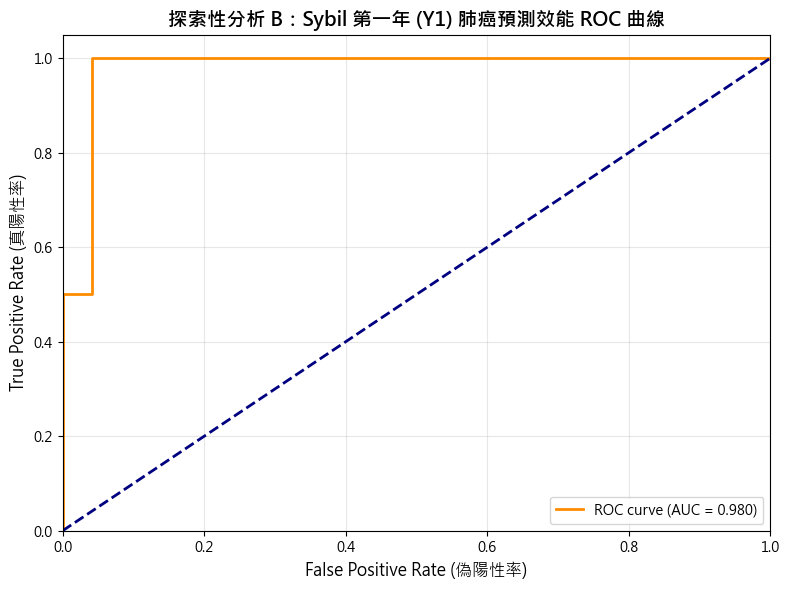

In [26]:
warnings.filterwarnings('ignore', category=FutureWarning)


target_cols = ['Y1_Risk', 'Y3_Risk', 'Y6_Risk']
df_stats = df_unique_results[target_cols].describe()

q1 = df_unique_results[target_cols].quantile(0.25)
q3 = df_unique_results[target_cols].quantile(0.75)
df_stats.loc['IQR'] = q3 - q1  


final_report = df_stats.loc[['mean', 'std', '50%', 'IQR', 'min', 'max']]
final_report.index = ['Mean (平均值)', 'SD (標準差)', 'Median (中位數)', 'IQR (四分位距)', 'Minimum (最小值)', 'Maximum (最大值)']

print("=========================================================")
print(" 【分析項目一】Sybil 風險預測描述性統計成果表")
print("=========================================================")
display(final_report)



BASE_DIR = Path(".")
BASE_DIR = Path.cwd()


found_files = list(BASE_DIR.rglob("nlst_780_prsn_idc_20210527.csv"))
if not found_files:
    raise FileNotFoundError("找不到 nlst_780_prsn_idc_20210527.csv 檔案，請確認已解壓縮並放在專案資料夾內！")

CLINICAL_FILE_PATH = found_files[0]
OUTPUT_FILE_PATH = BASE_DIR / "data" / "analysis_dataset.csv"

df_clinical = pd.read_csv(CLINICAL_FILE_PATH)
df_unique_results['PatientID'] = df_unique_results['PatientID'].astype(int)
df_clinical['pid'] = df_clinical['pid'].astype(int)


df_merged = pd.merge(df_unique_results, df_clinical, left_on='PatientID', right_on='pid', how='left')



def calculate_outcome_strict(row):
    tp = row.get('TIMEPOINT', 0)
    scr_col = f'scr_days{tp}'
    index_day = row.get(scr_col) if pd.notna(row.get(scr_col)) else row.get('scr_days0')
    
    if pd.isna(index_day):
        return pd.Series([pd.NA, pd.NA])
    
    if pd.notna(row.get('candx_days')) and row.get('candx_days') > 0:
        status = 1 
        days_to_event = row['candx_days'] - index_day
    else:
        status = 0 
        end_day = row.get('fup_days') if pd.notna(row.get('fup_days')) else row.get('canc_free_days')
        if pd.isna(end_day):
            return pd.Series([pd.NA, pd.NA])
        days_to_event = end_day - index_day
        
    return pd.Series([status, days_to_event])

df_merged[['Cancer_Status', 'Days_To_Event']] = df_merged.apply(calculate_outcome_strict, axis=1)


df_analysis = df_merged[(df_merged['Days_To_Event'] > 0) & (df_merged['Cancer_Status'].notna())].copy()


def create_yearly_labels(row, year):
    days_in_year = year * 365
    if row['Cancer_Status'] == 1 and row['Days_To_Event'] <= days_in_year:
        return 1
    elif row['Days_To_Event'] > days_in_year:
        return 0
    else:
        return pd.NA

for y in range(1, 7):
    df_analysis[f'True_Y{y}'] = df_analysis.apply(lambda row: create_yearly_labels(row, y), axis=1)

OUTPUT_FILE_PATH.parent.mkdir(parents=True, exist_ok=True)
df_analysis.to_csv(OUTPUT_FILE_PATH, index=False, encoding='utf-8-sig')
print(f"\n資料合併與篩選完成！有效獨立檢查數: {len(df_analysis)}。檔案已儲存至: {OUTPUT_FILE_PATH}")



valid_y1 = df_analysis.dropna(subset=['True_Y1']).copy()

if len(valid_y1) > 0 and len(valid_y1['True_Y1'].unique()) > 1:
    fpr, tpr, thresholds = roc_curve(valid_y1['True_Y1'].astype(int), valid_y1['Y1_Risk'])
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (偽陽性率)', fontsize=12)
    plt.ylabel('True Positive Rate (真陽性率)', fontsize=12)
    plt.title('探索性分析 B：Sybil 第一年 (Y1) 肺癌預測效能 ROC 曲線', fontsize=14, fontweight='bold')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    


In [27]:

df_results['StudyDate'] = pd.to_datetime(df_results['StudyDate'], format='%Y%m%d', errors='coerce')
df_results = df_results.dropna(subset=['PatientID', 'StudyDate'])

def assign_kernel_priority_strict(kernel_str):
    """
    建立絕對階層排序。
    確保平滑(Soft)特性統一優先，且廠牌間不並列。
    1~4 為 Soft kernels, 5~7 為 Sharp kernels
    """
    k = str(kernel_str).upper()
    # Soft / Standard Kernels
    if 'STANDARD' in k: return 1
    elif any(x in k for x in ['B30F', 'B31F', 'B20F']): return 2
    elif any(x in k for x in ['FC01', 'FC02', 'FC13', 'FC18']): return 3
    elif 'SOFT' in k or k == 'C':
        return 4
    # Sharp / Lung / Bone Kernels
    elif 'LUNG' in k: return 5
    elif any(x in k for x in ['B50F', 'B70F']): return 6
    elif any(x in k for x in ['FC51', 'FC52', 'FC81']): return 7
    elif any(x in k for x in ['BONE', 'EDGE', 'SHARP', 'D']): return 8
    else: return 99

df_results['Kernel_Priority'] = df_results['ConvolutionKernel'].apply(assign_kernel_priority_strict)

# 計算該次檢查總共有幾個序列競爭
df_results['Candidate_Count'] = df_results.groupby(['PatientID', 'StudyDate'])['SeriesInstanceUID'].transform('count')

# 排序規則：病患 -> 日期 -> Kernel階層(越小越好) -> 切片數(越多越好) -> UID(字母序防呆)
df_results_sorted = df_results.sort_values(
    by=['PatientID', 'StudyDate', 'Kernel_Priority', 'Total_Slices', 'SeriesInstanceUID'], 
    ascending=[True, True, True, False, True]
)

df_unique_results = df_results_sorted.drop_duplicates(subset=['PatientID', 'StudyDate'], keep='first').copy()

# 產生選用理由
def generate_selection_reason(row):
    if row['Candidate_Count'] == 1:
        return f"唯一合格序列 (Kernel: {row['ConvolutionKernel']}, Slices: {row['Total_Slices']})"
    else:
        return f"共 {row['Candidate_Count']} 候選, 優先選用 Kernel '{row['ConvolutionKernel']}' (Priority {row['Kernel_Priority']}), Slices: {row['Total_Slices']}"

df_unique_results['Selection_Reason'] = df_unique_results.apply(generate_selection_reason, axis=1)

print("✅ 修正後的最終選用結果與理由：")
print(df_unique_results[['PatientID', 'ConvolutionKernel', 'Total_Slices', 'Selection_Reason']])

✅ 修正後的最終選用結果與理由：
    PatientID ConvolutionKernel  Total_Slices  \
3      100002          STANDARD           126   
5      100002          STANDARD           133   
1      100002          STANDARD           129   
7      100004          STANDARD           118   
11     100004          STANDARD           109   
8      100004              FC01           150   
13     100012              B30f           162   
14     100012              B30f           157   
18     100015                 C           150   
16     100015                 C           168   
21     100015                 C           160   
25     100019                 C           136   
22     100019                 C           148   
27     100019                 C           149   
33     100026          STANDARD           142   
29     100026          STANDARD           131   
31     100026          STANDARD           135   
34     100029              B30f           154   
38     100029              B30f           162   
46 

In [28]:
# 1. 重新讀取最乾淨的臨床資料表，確保所有原始欄位都在 (破解變數污染)
target_file = "nlst_780_prsn_idc_20210527.csv"
found_files = list(Path.cwd().rglob(target_file))
if not found_files:
    raise FileNotFoundError(f"找不到 {target_file}")
df_clinical = pd.read_csv(found_files[0])

# 2. 型別與格式對齊：確保所有表格的病患 ID 全都是乾淨的字串
df_meta['PatientID'] = df_meta['PatientID'].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
df_unique_results['PatientID'] = df_unique_results['PatientID'].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
df_clinical['pid'] = df_clinical['pid'].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)

# 3. 處理 df_meta，取得所有病患的原始檢查排序 (確保 1999為0, 2000為1, 2001為2)
time_mapping = df_meta[['PatientID', 'StudyDate']].drop_duplicates().copy()
time_mapping['StudyDate'] = pd.to_datetime(time_mapping['StudyDate'], format='%Y%m%d', errors='coerce')
time_mapping = time_mapping.dropna()
time_mapping['TIMEPOINT'] = time_mapping.groupby('PatientID')['StudyDate'].rank(method='dense').astype(int) - 1

# 4. 暴力清理 df_unique_results，只保留 AI 分析的純淨結果，徹底避免 _x, _y 干擾
base_cols = ['PatientID', 'StudyDate', 'StudyInstanceUID', 'SeriesInstanceUID', 'Total_Slices', 'ConvolutionKernel', 'Y1_Risk', 'Y2_Risk', 'Y3_Risk', 'Y4_Risk', 'Y5_Risk', 'Y6_Risk', 'Kernel_Priority', 'Candidate_Count', 'Selection_Reason']
valid_cols = [c for c in df_unique_results.columns if c in base_cols]
df_unique_results = df_unique_results[valid_cols].copy()

# 5. 合併真正的 TIMEPOINT
df_unique_results = df_unique_results.merge(time_mapping, on=['PatientID', 'StudyDate'], how='left')

# 6. 合併臨床天數資料
cols_to_merge = ['pid', 'scr_days0', 'scr_days1', 'scr_days2', 'candx_days', 'canc_free_days']
df_unique_results = df_unique_results.merge(df_clinical[cols_to_merge], left_on='PatientID', right_on='pid', how='left')

# 7. 計算結局與天數
def calculate_outcome_strict(row):
    tp = row.get('TIMEPOINT')
    
    # 防呆：若查無 TIMEPOINT
    if pd.isna(tp): 
        return pd.Series([pd.NA, pd.NA])
        
    scr_col = f'scr_days{int(tp)}'
    
    # 取出對應的 index_day，如果沒有這一次的紀錄，就退回找 scr_days0 作為保底
    index_day = row.get(scr_col) if pd.notna(row.get(scr_col)) else row.get('scr_days0')
    
    if pd.isna(index_day):
        return pd.Series([pd.NA, pd.NA])
    
    # 計算 Days_To_Event
    if pd.notna(row.get('candx_days')) and row.get('candx_days') > 0:
        status = 1 
        days_to_event = row['candx_days'] - index_day
    else:
        status = 0 
        days_to_event = row['canc_free_days'] - index_day
        
    return pd.Series([status, days_to_event])

# 寫入 Cancer_Status 與 Days_To_Event
df_unique_results[['Cancer_Status', 'Days_To_Event']] = df_unique_results.apply(calculate_outcome_strict, axis=1)

print("✅ 第二題：依 df_meta 日期順序建立的原始 TIMEPOINT 映射與追蹤天數：")
display_cols = ['PatientID', 'StudyDate', 'TIMEPOINT', 'scr_days0', 'scr_days1', 'scr_days2', 'Days_To_Event']
display(df_unique_results[display_cols].sort_values(['PatientID', 'StudyDate']))

✅ 第二題：依 df_meta 日期順序建立的原始 TIMEPOINT 映射與追蹤天數：


,PatientID,StudyDate,TIMEPOINT,scr_days0,scr_days1,scr_days2,Days_To_Event
0,100002,1999-01-02,0,13.0,349.0,731.0,2378.0
1,100002,2000-01-02,1,13.0,349.0,731.0,2042.0
2,100002,2001-01-02,2,13.0,349.0,731.0,1660.0
3,100004,1999-01-02,0,8.0,452.0,743.0,2680.0
4,100004,2000-01-02,1,8.0,452.0,743.0,2236.0
5,100004,2001-01-02,2,8.0,452.0,743.0,1945.0
6,100012,1999-01-02,0,16.0,363.0,NaN,438.0
7,100012,2000-01-02,1,16.0,363.0,NaN,91.0
8,100015,1999-01-02,0,12.0,341.0,725.0,2330.0
9,100015,2000-01-02,1,12.0,341.0,725.0,2001.0
